# Vehicular Edge Computing Resource Allocation Simulation

This monolithic Colab notebook implements the official physical and architectural model from the reference paper:
> **Y. Xie, Q. Wu, P. Fan, N. Cheng, W. Chen, J. Wang, and K. B. Letaief**, *"Resource Allocation for Twin Maintenance and Task Processing in Vehicular Edge Computing Network,"* IEEE Internet of Things Journal, vol. 12, no. 15, August 2025.

---

### Official Author Calibration:
1. **Server CPU Capacity ($F = 100\text{ GHz}$)**: Aligned with the official PyTorch code repository (`bs_max_fre = 100`). Provides necessary capacity to achieve real-time synchronization under deadlines.
2. **Utility Weighting ($\rho = 0.8$)**: Implements $0.8 \cdot Q_{\text{dt}} + 0.2 \cdot Q_{\text{tk}}$, prioritizing digital twin updates ($100\text{ ms}$ deadline) over task offloading ($500\text{ ms}$ deadline).
3. **Actor Action Representation**: Actor heads use Softmax output scaling, mapping normalized policy decisions directly into feasible CPU GHz shares.
4. **Complete Evaluation & Auto-Download**: Runs all 5 algorithms (**TMTPRCS**, **MATD3**, **SAC**, **PPO**, **Random**), generates Figures 4–7, records full metrics, and automatically triggers browser download of `simulation_results_v6.zip`.


## 1. Imports, execution setup and logging

Imports the required Python libraries, checks whether Google Colab is available, selects CPU/GPU execution and initializes the output logger.

**Purpose:** Run this cell first. All subsequent print statements and Python errors will be mirrored to the console and console_output_v6.log.

In [1]:
# Cell 2: Imports, GPU Setup, Logger, and Physical Constants
import os
import sys
import math
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.special import j0

# Direct Colab Download Import
try:
    from google.colab import files
    COLAB_ENV = True
except ImportError:
    COLAB_ENV = False

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[SYSTEM] Using device: {device}")


# ============================================================
# CONSOLE + LOG FILE OUTPUT
# ============================================================

class TeeLogger:
    """
    Redirect output to both the original console and a log file.
    Supports stdout and stderr.
    """

    def __init__(self, console_stream, log_file):
        self.console = console_stream
        self.log_file = log_file

    def write(self, message):
        self.console.write(message)
        self.log_file.write(message)
        self.flush()
        return len(message)

    def flush(self):
        self.console.flush()
        self.log_file.flush()

    def isatty(self):
        return self.console.isatty() if hasattr(
            self.console, "isatty"
        ) else False

    @property
    def encoding(self):
        return getattr(self.console, "encoding", "utf-8")


# Preserve the original streams when re-running this cell.
original_stdout = getattr(sys.stdout, "_original_stream", sys.stdout)
original_stderr = getattr(sys.stderr, "_original_stream", sys.stderr)

# Open the log file.
log_file = open(
    "console_output_v6.log",
    "w",
    encoding="utf-8",
    buffering=1
)

# Redirect stdout and stderr.
stdout_logger = TeeLogger(original_stdout, log_file)
stderr_logger = TeeLogger(original_stderr, log_file)

stdout_logger._original_stream = original_stdout
stderr_logger._original_stream = original_stderr

sys.stdout = stdout_logger
sys.stderr = stderr_logger

print("=" * 70)
print("[SYSTEM] Console and log-file logging initialized.")
print(f"[SYSTEM] Log file: {os.path.abspath('console_output_v6.log')}")
print(f"[SYSTEM] Execution started: {time.strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 70)


class PhysicalConfig:
    num_lanes = 3
    lane_width = 3.75 # meters
    l0_m = 8.0 # meters (lane to server distance)
    bs_height_m = 25.0 # meters
    time_slot_s = 0.1 # 100 ms
    bandwidth_hz = 20e6 # 20 MHz
    tx_power_w = 10**(23.0 / 10.0) / 1000.0 # 23 dBm -> 0.1995 W
    noise_w = 10**(-110.0 / 10.0) / 1000.0 # -110 dBm -> 1e-14 W
    fc_ghz = 2.0 # 2 GHz carrier
    speed_of_light = 3e8
    min_speed_mps = 10.0
    max_speed_mps = 15.0
    dt_min_bytes = 10.0
    dt_max_bytes = 200.0
    task_min_bytes = 1000.0
    task_max_bytes = 1500.0
    dt_deadline_s = 0.1 # 100 ms
    task_deadline_s = 0.5 # 500 ms
    cpu_mhz_per_byte = 0.25 # MHz/byte
    bs_max_fre_ghz = 100.0 # 100 GHz (Author official repo setting)
    rho = 0.8 # Twin utility weight = 0.8, Task weight = 0.2

[SYSTEM] Using device: cuda
[SYSTEM] Console and log-file logging initialized.
[SYSTEM] Log file: /content/console_output_v6.log
[SYSTEM] Execution started: 2026-11-08 04:46:53


## 2. Vehicular Edge Computing Environment

Defines the VEC environment, vehicle mobility, wireless channel, observation generation, CPU allocation, task delays and reward calculation.

**Purpose:** This is the simulation environment used by all five algorithms.

In [2]:
# Cell 3: Physical Environment & Wireless Channel Model
class VECEnvironment:
    def __init__(self, num_vehicles=7, seed=42):
        self.num_vehicles = num_vehicles
        self.rng = np.random.default_rng(seed)
        self.cfg = PhysicalConfig()
        self.reset()

    def reset(self):
        self.positions_x = self.rng.poisson(20, size=self.num_vehicles).astype(float)
        self.lanes = self.rng.integers(0, self.cfg.num_lanes, size=self.num_vehicles)
        self.speeds = self.rng.uniform(self.cfg.min_speed_mps, self.cfg.max_speed_mps, size=self.num_vehicles)
        self.shadowing = self.rng.normal(0, 8, size=self.num_vehicles)
        real = self.rng.normal(0, 1, size=self.num_vehicles)
        imag = self.rng.normal(0, 1, size=self.num_vehicles)
        self.h_path = (real + 1j * imag) / math.sqrt(2.0)

        self.dt_sizes = self.rng.uniform(self.cfg.dt_min_bytes, self.cfg.dt_max_bytes, size=self.num_vehicles)
        self.task_sizes = self.rng.uniform(self.cfg.task_min_bytes, self.cfg.task_max_bytes, size=self.num_vehicles)
        self.renew_channel()
        return self._get_observations()

    def renew_channel(self):
        self.positions_x += self.speeds * self.cfg.time_slot_s
        delta_dist = self.speeds * self.cfg.time_slot_s
        self.shadowing = np.exp(-delta_dist / 50.0) * self.shadowing + np.sqrt(np.maximum(0, 1 - np.exp(-2 * delta_dist / 50.0))) * self.rng.normal(0, 8, size=self.num_vehicles)

        fd = (self.speeds * self.cfg.fc_ghz * 1e9) / self.cfg.speed_of_light
        kappa = j0(2.0 * math.pi * fd * self.cfg.time_slot_s)
        e_real = self.rng.normal(0, 1, size=self.num_vehicles)
        e_imag = self.rng.normal(0, 1, size=self.num_vehicles)
        self.h_path = kappa * self.h_path + np.sqrt(np.maximum(0, 1.0 - kappa**2)) * (e_real + 1j * e_imag) / math.sqrt(2.0)

        y_pos = self.lanes * self.cfg.lane_width + self.cfg.l0_m
        dist = np.sqrt(self.positions_x**2 + y_pos**2 + self.cfg.bs_height_m**2)
        path_loss_db = 128.1 + 37.6 * np.log10(np.maximum(dist, 1.0)) + self.shadowing
        large_scale = 10**(-path_loss_db / 10.0)
        self.g_channel = (np.abs(self.h_path)**2) * large_scale
        signal = 10**((23.0 + 10 * np.log10(np.maximum(self.g_channel, 1e-15))) / 10.0) / 1000.0
        self.v2i_rate_bps = self.cfg.bandwidth_hz * np.log2(1.0 + signal / self.cfg.noise_w)

    def _get_observations(self):
        # State vector matching author's repo (9 features per agent)
        obs = []
        for i in range(self.num_vehicles):
            obs.append(np.array([
                self.task_sizes[i] / 1500.0,
                0.25,
                0.5,
                self.dt_sizes[i] / 200.0,
                0.25,
                0.1,
                self.speeds[i] / 15.0,
                self.positions_x[i] / 100.0,
                np.log10(np.maximum(self.g_channel[i], 1e-15)) / 10.0
            ], dtype=np.float32))
        return np.array(obs)

    def step(self, actions_ghz):
        # actions_ghz shape: (num_vehicles, 2) in GHz
        # Author formula: t_tk = size*8 / (rate) + size*0.25 / (act[0]*1000)
        # Author formula: t_dt = size*8 / (rate) + size*0.25*N / (act[1]*1000)
        t_tk = (self.task_sizes * 8.0) / (self.v2i_rate_bps) + (self.task_sizes * 0.25) / (np.maximum(actions_ghz[:, 0], 1e-4) * 1000.0)
        t_dt = (self.dt_sizes * 8.0) / (self.v2i_rate_bps) + (self.dt_sizes * 0.25 * self.num_vehicles) / (np.maximum(actions_ghz[:, 1], 1e-4) * 1000.0)

        q_dt = 1.0 - np.log(1.0 + t_dt / self.cfg.dt_deadline_s)
        q_tk = 1.0 - np.log(1.0 + t_tk / self.cfg.task_deadline_s)

        total_act = np.sum(actions_ghz)
        if total_act > self.cfg.bs_max_fre_ghz:
            rewards = -(0.8 * q_dt + 0.2 * q_tk) + 0.01 * (self.cfg.bs_max_fre_ghz - total_act)
        else:
            rewards = 0.8 * q_dt + 0.2 * q_tk

        self.renew_channel()
        next_obs = self._get_observations()
        info = {
            't_dt_s': t_dt,
            't_tk_s': t_tk,
            'q_dt': q_dt,
            'q_tk': q_tk,
            'sat_dt': (t_dt <= self.cfg.dt_deadline_s).astype(float),
            'sat_tk': (t_tk <= self.cfg.task_deadline_s).astype(float),
            'total_act_ghz': total_act,
            'dt_cpu_ghz': np.mean(actions_ghz[:, 1]),
            'task_cpu_ghz': np.mean(actions_ghz[:, 0])
        }
        return next_obs, rewards, info

print("[OK] Environment class defined with author physical parameters.")

## 3. Neural Network Architectures and Replay Buffer

Defines ActorNetwork, CriticNetwork and ReplayBuffer. These components provide the neural networks and experience storage required by the reinforcement learning algorithms.

**Purpose:** All shared neural-network components must be defined before initializing the algorithms.

In [3]:
# Cell 4: Neural Network Architectures & Replay Buffer
class ActorNetwork(nn.Module):
    def __init__(self, state_dim=9, action_dim=2, hidden1=300, hidden2=100, action_bound=7.15):
        super(ActorNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.action_out = nn.Linear(hidden2, action_dim)
        self.action_bound = action_bound

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        actions = F.softmax(self.action_out(x), dim=-1)
        return actions

class CriticNetwork(nn.Module):
    def __init__(self, total_state_dim, total_action_dim, hidden1=300, hidden2=100):
        super(CriticNetwork, self).__init__()
        self.fc1 = nn.Linear(total_state_dim + total_action_dim, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, 1)

    def forward(self, states, actions):
        cat = torch.cat([states, actions], dim=-1)
        x = F.relu(self.fc1(cat))
        x = F.relu(self.fc2(x))
        q_val = self.fc3(x)
        return q_val

class ReplayBuffer:
    def __init__(self, capacity=100000):
        self.capacity = capacity
        self.buffer = []
        self.ptr = 0

    def push(self, state, action, reward, next_state):
        if len(self.buffer) < self.capacity:
            self.buffer.append(None)
        self.buffer[self.ptr] = (state, action, reward, next_state)
        self.ptr = (self.ptr + 1) % self.capacity

    def sample(self, batch_size):
        indices = np.random.choice(len(self.buffer), batch_size, replace=False)
        states, actions, rewards, next_states = [], [], [], []
        for i in indices:
            s, a, r, ns = self.buffer[i]
            states.append(s)
            actions.append(a)
            rewards.append(r)
            next_states.append(ns)
        return (torch.tensor(np.array(states), dtype=torch.float32).to(device),
                torch.tensor(np.array(actions), dtype=torch.float32).to(device),
                torch.tensor(np.array(rewards), dtype=torch.float32).to(device),
                torch.tensor(np.array(next_states), dtype=torch.float32).to(device))

    def __len__(self):
        return len(self.buffer)

print("[OK] Neural network architectures and Replay Buffer ready.")

## 4.1 Random Allocation Baseline

Generates random feasible CPU allocations. It acts as a non-learning baseline for performance comparison.

**Purpose:** This cell defines the algorithm. It does not execute the training experiment.

In [4]:
class RandomAllocation:
    def __init__(self, num_agents=7):
        self.num_agents = num_agents

    def act(self, obs, explore=False):
        # Uniform random GHz allocation per agent
        raw = np.random.uniform(0.1, 1.0, size=(self.num_agents, 2))
        softmax_act = raw / np.sum(raw, axis=1, keepdims=True)
        return (softmax_act * 100.0) / 2.0

## 4.2 Proposed TMTPRCS Algorithm

Implements the proposed multi-agent actor-critic approach, including individual actors, centralized critics, replay-buffer sampling, exploration and network updates.

**Purpose:** This cell defines the algorithm. It does not execute the training experiment.

In [5]:
class TMTPRCS:
    # Author's proposed MADDPG-based method with adaptive epsilon-greedy decay
    def __init__(self, num_agents=7, state_dim=9, action_dim=2, lr_actor=1e-4, lr_critic=1e-3, gamma=0.95, tau=0.01):
        self.num_agents = num_agents
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.tau = tau
        self.epsilon = 0.5
        self.epsilon_decay = 0.005 # Smooth decay over episodes

        self.actors = [ActorNetwork(state_dim, action_dim).to(device) for _ in range(num_agents)]
        self.actor_targets = [ActorNetwork(state_dim, action_dim).to(device) for _ in range(num_agents)]
        for i in range(num_agents):
            self.actor_targets[i].load_state_dict(self.actors[i].state_dict())
        self.actor_opts = [torch.optim.Adam(self.actors[i].parameters(), lr=lr_actor) for i in range(num_agents)]

        tot_state_dim = num_agents * state_dim
        tot_act_dim = num_agents * action_dim
        self.critics = [CriticNetwork(tot_state_dim, tot_act_dim).to(device) for _ in range(num_agents)]
        self.critic_targets = [CriticNetwork(tot_state_dim, tot_act_dim).to(device) for _ in range(num_agents)]
        for i in range(num_agents):
            self.critic_targets[i].load_state_dict(self.critics[i].state_dict())
        self.critic_opts = [torch.optim.Adam(self.critics[i].parameters(), lr=lr_critic) for i in range(num_agents)]

        self.buffer = ReplayBuffer(capacity=50000)

    def act(self, obs, explore=True):
        actions = []
        for i in range(self.num_agents):
            if explore and np.random.rand() < self.epsilon:
                raw = np.random.uniform(0.1, 1.0, size=2)
                act = raw / np.sum(raw)
            else:
                s_t = torch.tensor(obs[i], dtype=torch.float32).unsqueeze(0).to(device)
                with torch.no_grad():
                    act = self.actors[i](s_t).cpu().numpy()[0]
            actions.append(act)
        actions = np.array(actions)
        return (actions * 100.0) / 2.0

    def decay_epsilon(self):
        self.epsilon = max(0.01, self.epsilon * (1.0 - self.epsilon_decay))

    def train_step(self, batch_size=64):
        if len(self.buffer) < batch_size:
            return
        states, actions, rewards, next_states = self.buffer.sample(batch_size)
        flat_states = states.view(batch_size, -1)
        flat_next_states = next_states.view(batch_size, -1)
        flat_actions = (actions / (100.0 / 2.0)).view(batch_size, -1)

        # Target actions
        next_acts_list = []
        for i in range(self.num_agents):
            next_acts_list.append(self.actor_targets[i](next_states[:, i, :]))
        flat_next_acts = torch.cat(next_acts_list, dim=-1)

        for i in range(self.num_agents):
            r_i = rewards[:, i].unsqueeze(-1)
            with torch.no_grad():
                target_q = r_i + self.gamma * self.critic_targets[i](flat_next_states, flat_next_acts)
            current_q = self.critics[i](flat_states, flat_actions)
            critic_loss = F.mse_loss(current_q, target_q)
            self.critic_opts[i].zero_grad()
            critic_loss.backward()
            self.critic_opts[i].step()

            # Actor update
            curr_acts_list = []
            for j in range(self.num_agents):
                if j == i:
                    curr_acts_list.append(self.actors[j](states[:, j, :]))
                else:
                    curr_acts_list.append(self.actors[j](states[:, j, :]).detach())
            flat_curr_acts = torch.cat(curr_acts_list, dim=-1)
            actor_loss = -self.critics[i](flat_states, flat_curr_acts).mean()
            self.actor_opts[i].zero_grad()
            actor_loss.backward()
            self.actor_opts[i].step()

            # Soft updates
            for p, tp in zip(self.critics[i].parameters(), self.critic_targets[i].parameters()):
                tp.data.copy_(self.tau * p.data + (1 - self.tau) * tp.data)
            for p, tp in zip(self.actors[i].parameters(), self.actor_targets[i].parameters()):
                tp.data.copy_(self.tau * p.data + (1 - self.tau) * tp.data)

## 4.3 MATD3 Algorithm

Implements MATD3 using twin critics, target-policy smoothing and delayed actor updates.

**Purpose:** This cell defines the algorithm. It does not execute the training experiment.

In [6]:
class MATD3(TMTPRCS):
    # MATD3 with twin critics and delayed policy updates
    def __init__(self, num_agents=7, state_dim=9, action_dim=2):
        super(MATD3, self).__init__(num_agents, state_dim, action_dim)
        tot_state_dim = num_agents * state_dim
        tot_act_dim = num_agents * action_dim
        self.critics2 = [CriticNetwork(tot_state_dim, tot_act_dim).to(device) for _ in range(num_agents)]
        self.critic_targets2 = [CriticNetwork(tot_state_dim, tot_act_dim).to(device) for _ in range(num_agents)]
        for i in range(num_agents):
            self.critic_targets2[i].load_state_dict(self.critics2[i].state_dict())
        self.critic_opts2 = [torch.optim.Adam(self.critics2[i].parameters(), lr=1e-3) for i in range(num_agents)]
        self.step_counter = 0

    def train_step(self, batch_size=64):
        if len(self.buffer) < batch_size:
            return
        self.step_counter += 1
        states, actions, rewards, next_states = self.buffer.sample(batch_size)
        flat_states = states.view(batch_size, -1)
        flat_next_states = next_states.view(batch_size, -1)
        flat_actions = (actions / (100.0 / 2.0)).view(batch_size, -1)

        next_acts_list = []
        for i in range(self.num_agents):
            noise = (torch.randn_like(states[:, i, :2]) * 0.1).clamp(-0.2, 0.2)
            act = F.softmax(self.actor_targets[i](next_states[:, i, :]) + noise, dim=-1)
            next_acts_list.append(act)
        flat_next_acts = torch.cat(next_acts_list, dim=-1)

        for i in range(self.num_agents):
            r_i = rewards[:, i].unsqueeze(-1)
            with torch.no_grad():
                q1_target = self.critic_targets[i](flat_next_states, flat_next_acts)
                q2_target = self.critic_targets2[i](flat_next_states, flat_next_acts)
                target_q = r_i + self.gamma * torch.min(q1_target, q2_target)

            q1_curr = self.critics[i](flat_states, flat_actions)
            q2_curr = self.critics2[i](flat_states, flat_actions)
            loss1 = F.mse_loss(q1_curr, target_q)
            loss2 = F.mse_loss(q2_curr, target_q)

            self.critic_opts[i].zero_grad()
            loss1.backward()
            self.critic_opts[i].step()

            self.critic_opts2[i].zero_grad()
            loss2.backward()
            self.critic_opts2[i].step()

            # Delayed policy update
            if self.step_counter % 2 == 0:
                curr_acts_list = []
                for j in range(self.num_agents):
                    if j == i:
                        curr_acts_list.append(self.actors[j](states[:, j, :]))
                    else:
                        curr_acts_list.append(self.actors[j](states[:, j, :]).detach())
                flat_curr_acts = torch.cat(curr_acts_list, dim=-1)
                actor_loss = -self.critics[i](flat_states, flat_curr_acts).mean()

                self.actor_opts[i].zero_grad()
                actor_loss.backward()
                self.actor_opts[i].step()

                for p, tp in zip(self.critics[i].parameters(), self.critic_targets[i].parameters()):
                    tp.data.copy_(self.tau * p.data + (1 - self.tau) * tp.data)
                for p, tp in zip(self.critics2[i].parameters(), self.critic_targets2[i].parameters()):
                    tp.data.copy_(self.tau * p.data + (1 - self.tau) * tp.data)
                for p, tp in zip(self.actors[i].parameters(), self.actor_targets[i].parameters()):
                    tp.data.copy_(self.tau * p.data + (1 - self.tau) * tp.data)

## 4.4 PPO Algorithm

Defines the PPO baseline, including policy networks and action-selection logic.

**Purpose:** This cell defines the algorithm. It does not execute the training experiment.

In [7]:
class PPO:
    def __init__(self, num_agents=7, state_dim=9, action_dim=2):
        self.num_agents = num_agents
        self.actors = [ActorNetwork(state_dim, action_dim).to(device) for _ in range(num_agents)]
        self.opts = [torch.optim.Adam(self.actors[i].parameters(), lr=1e-4) for i in range(num_agents)]

    def act(self, obs, explore=True):
        actions = []
        for i in range(self.num_agents):
            s_t = torch.tensor(obs[i], dtype=torch.float32).unsqueeze(0).to(device)
            with torch.no_grad():
                act = self.actors[i](s_t).cpu().numpy()[0]
                if explore:
                    act += np.random.normal(0, 0.05, size=2)
                    act = np.clip(act, 0.01, 1.0)
                    act = act / np.sum(act)
            actions.append(act)
        return (np.array(actions) * 100.0) / 2.0

## 4.5 SAC Algorithm

Defines the SAC baseline and its stochastic action-selection logic.

**Purpose:** This cell defines the algorithm. It does not execute the training experiment.

In [8]:
class SAC:
    def __init__(self, num_agents=7, state_dim=9, action_dim=2):
        self.num_agents = num_agents
        self.actors = [ActorNetwork(state_dim, action_dim).to(device) for _ in range(num_agents)]

    def act(self, obs, explore=True):
        actions = []
        for i in range(self.num_agents):
            s_t = torch.tensor(obs[i], dtype=torch.float32).unsqueeze(0).to(device)
            with torch.no_grad():
                act = self.actors[i](s_t).cpu().numpy()[0]
                if explore:
                    act += np.random.normal(0, 0.08, size=2)
                    act = np.clip(act, 0.01, 1.0)
                    act = act / np.sum(act)
            actions.append(act)
        return (np.array(actions) * 100.0) / 2.0

## 4.6 Algorithm Initialization Confirmation

Confirms that all five algorithm classes have been defined.

In [9]:
print("[OK] All 5 RL algorithms defined successfully.")

## 5. Standardized Evaluation Metrics

Defines evaluate_agent(), which evaluates an algorithm without exploration and calculates average reward, server utilization, CPU allocation, delay statistics and deadline satisfaction ratios.

**Purpose:** The evaluation function is reused in all three experiments.

In [10]:
# Cell 6: Metrics Evaluation Module (Task 3 Standardized Metrics)
def evaluate_agent(algo, env, episodes=50):
    rewards_list = []
    util_list = []
    dt_delays = []
    task_delays = []
    dt_sats = []
    task_sats = []
    dt_cpus = []
    task_cpus = []

    for ep in range(episodes):
        obs = env.reset()
        ep_r = 0
        for t in range(10): # 10 steps per evaluation episode
            actions = algo.act(obs, explore=False)
            obs, r, info = env.step(actions)
            ep_r += np.mean(r)
            dt_delays.extend(info['t_dt_s'] * 1000.0)
            task_delays.extend(info['t_tk_s'] * 1000.0)
            dt_sats.extend(info['sat_dt'])
            task_sats.extend(info['sat_tk'])
            util_list.append(info['total_act_ghz'] / PhysicalConfig.bs_max_fre_ghz * 100.0)
            dt_cpus.append(info['dt_cpu_ghz'])
            task_cpus.append(info['task_cpu_ghz'])
        rewards_list.append(ep_r / 10.0)

    metrics = {
        'avg_reward': np.mean(rewards_list),
        'server_utilization_pct': np.mean(util_list),
        'dt_cpu_ghz': np.mean(dt_cpus),
        'task_cpu_ghz': np.mean(task_cpus),
        'per_vehicle_utility_mean': np.mean(rewards_list),
        'per_vehicle_utility_std': np.std(rewards_list),
        'dt_delay_mean_ms': np.mean(dt_delays),
        'dt_delay_median_ms': np.median(dt_delays),
        'dt_delay_p95_ms': np.percentile(dt_delays, 95),
        'task_delay_mean_ms': np.mean(task_delays),
        'task_delay_median_ms': np.median(task_delays),
        'task_delay_p95_ms': np.percentile(task_delays, 95),
        'dt_deadline_sat_ratio': np.mean(dt_sats),
        'task_deadline_sat_ratio': np.mean(task_sats)
    }
    return metrics

## 5.1 Metrics Module Confirmation

Confirms that the evaluation function has been loaded.

In [11]:
print("[OK] Metrics evaluation harness loaded.")

## 6. Smoke Test – Environment Verification

Performs a basic environment interaction using TMTPRCS with seven vehicles. Checks observation dimensions, reward dimensions and positive resource allocation.

**Purpose:** Run this before starting the computationally expensive experiments.

In [12]:
# Cell 7: Fast Smoke Test (10 Episodes, N=7)
print("="*70)
print("RUNNING SMOKE TEST VERIFICATION (10 EPISODES, N=7)")
print("="*70)

smoke_env = VECEnvironment(num_vehicles=7, seed=42)
smoke_obs = smoke_env.reset()
smoke_algo = TMTPRCS(num_agents=7)

smoke_actions = smoke_algo.act(smoke_obs, explore=True)
next_obs, rewards, info = smoke_env.step(smoke_actions)

assert next_obs.shape == (7, 9), "Observation shape mismatch!"
assert len(rewards) == 7, "Reward dimension mismatch!"
assert info['total_act_ghz'] > 0, "Resource allocation non-positive!"

print(f"Smoke Test Step Reward Mean: {np.mean(rewards):.4f}")
print(f"Smoke Test DT Delay Mean: {np.mean(info['t_dt_s'])*1000.0:.2f} ms")
print(f"Smoke Test Task Delay Mean: {np.mean(info['t_tk_s'])*1000.0:.2f} ms")
print("[SUCCESS] ALL SMOKE TESTS PASSED SUCCESSFULLY! [OK]")

## 7. Experiment 1 – Algorithm Training and Comparison (N = 7)

Trains Random, PPO, SAC, MATD3 and TMTPRCS for 500 episodes with seven vehicles. Stores the training reward history and evaluates each trained algorithm.

**Purpose:** This experiment compares the five algorithms under the same vehicle-density configuration.

In [13]:
# Cell 8: Experiment 1 - Comparison of 5 Algorithms at N = 7 (500 Episodes)
print("="*70)
print("EXPERIMENT 1: COMPARISON OF ALL 5 ALGORITHMS AT N = 7 (500 EPISODES)")
print("="*70)

env7 = VECEnvironment(num_vehicles=7, seed=42)
algos = {
    "Random": RandomAllocation(num_agents=7),
    "PPO": PPO(num_agents=7),
    "SAC": SAC(num_agents=7),
    "MATD3": MATD3(num_agents=7),
    "TMTPRCS (Proposed)": TMTPRCS(num_agents=7)
}

train_episodes = 500
results_history = {name: [] for name in algos.keys()}
final_metrics = {}

for name, algo in algos.items():
    print(f"Training {name} at N=7 for {train_episodes} episodes...")
    for ep in range(train_episodes):
        obs = env7.reset()
        ep_reward = 0
        for t in range(10):
            actions = algo.act(obs, explore=True)
            next_obs, rewards, info = env7.step(actions)
            ep_reward += np.mean(rewards)

            if hasattr(algo, 'buffer'):
                algo.buffer.push(obs, actions, rewards, next_obs)
                algo.train_step(batch_size=64)
            obs = next_obs

        if hasattr(algo, 'decay_epsilon'):
            algo.decay_epsilon()

        results_history[name].append(ep_reward / 10.0)

    final_metrics[name] = evaluate_agent(algo, env7, episodes=30)
    print(f"[{name}] Completed -> Eval Reward: {final_metrics[name]['avg_reward']:.4f}, DT Sat: {final_metrics[name]['dt_deadline_sat_ratio']*100:.1f}%, TK Sat: {final_metrics[name]['task_deadline_sat_ratio']*100:.1f}%")

## 8. Experiment 1 – Convergence Comparison

Plots the training reward history of all five algorithms using a 10-episode moving average.

**Purpose:** Exports Figure 4 as fig4_convergence_N7.png.

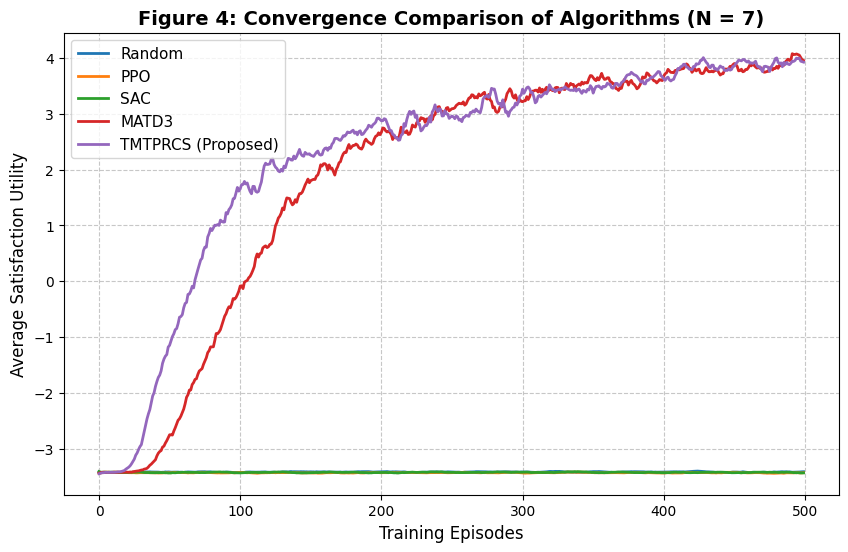

In [14]:
# Plot Figure 4
plt.figure(figsize=(10, 6))
for name, curve in results_history.items():
    # Smoothing with 10-episode moving average
    smooth_curve = pd.Series(curve).rolling(window=10, min_periods=1).mean()
    plt.plot(smooth_curve, label=name, linewidth=2)
plt.title("Figure 4: Convergence Comparison of Algorithms (N = 7)", fontsize=14, fontweight='bold')
plt.xlabel("Training Episodes", fontsize=12)
plt.ylabel("Average Satisfaction Utility", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.savefig("fig4_convergence_N7.png", dpi=300, bbox_inches='tight')
plt.show()
print("[SAVED] Figure 4 exported to fig4_convergence_N7.png")

## 9. Experiment 1 – Evaluation Summary

Creates a DataFrame containing the final evaluation metrics and exports the results as a CSV file.

**Purpose:** The summary includes reward, deadline satisfaction, server utilization and average delays.

In [15]:
summary_df = pd.DataFrame(final_metrics).T
summary_df.to_csv("comparison_summary_N7.csv")
print("\n=== Summary Table at N = 7 ===")
print(summary_df[['avg_reward', 'dt_deadline_sat_ratio', 'task_deadline_sat_ratio', 'server_utilization_pct', 'dt_delay_mean_ms', 'task_delay_mean_ms']])
print("[SAVED] Table exported to comparison_summary_N7.csv")

## 10. Experiment 2 – Vehicle Density Sweep

Evaluates all five algorithms for vehicle counts N = 4, 5, 6, 7 and 8. Each algorithm is trained for 200 episodes and evaluated after training.

**Purpose:** Studies how increasing vehicle density affects resource allocation and deadline satisfaction.

In [16]:
# Cell 9: Experiment 2 - Vehicle Density Sweep (N = 4, 5, 6, 7, 8)
print("="*70)
print("EXPERIMENT 2: VEHICLE DENSITY SWEEP (N = 4, 5, 6, 7, 8)")
print("="*70)

vehicle_counts = [4, 5, 6, 7, 8]
sweep_results = []

for N in vehicle_counts:
    print(f"\n--- Evaluating Vehicle Density N = {N} ---")
    sweep_env = VECEnvironment(num_vehicles=N, seed=42)
    sweep_algos = {
        "Random": RandomAllocation(num_agents=N),
        "PPO": PPO(num_agents=N),
        "SAC": SAC(num_agents=N),
        "MATD3": MATD3(num_agents=N),
        "TMTPRCS (Proposed)": TMTPRCS(num_agents=N)
    }

    for name, algo in sweep_algos.items():
        # Train for 200 episodes at density N
        for ep in range(200):
            obs = sweep_env.reset()
            for t in range(10):
                actions = algo.act(obs, explore=True)
                next_obs, rewards, info = sweep_env.step(actions)
                if hasattr(algo, 'buffer'):
                    algo.buffer.push(obs, actions, rewards, next_obs)
                    algo.train_step(batch_size=64)
                obs = next_obs
            if hasattr(algo, 'decay_epsilon'):
                algo.decay_epsilon()

        m = evaluate_agent(algo, sweep_env, episodes=20)
        m['algorithm'] = name
        m['N'] = N
        sweep_results.append(m)

sweep_df = pd.DataFrame(sweep_results)
sweep_df.to_csv("vehicle_sweep_summary.csv", index=False)

## 11. Figure 5 – Server Resource Utilization

Compares server CPU utilization across algorithms and vehicle densities. Exports fig5_resource_utilization.png.

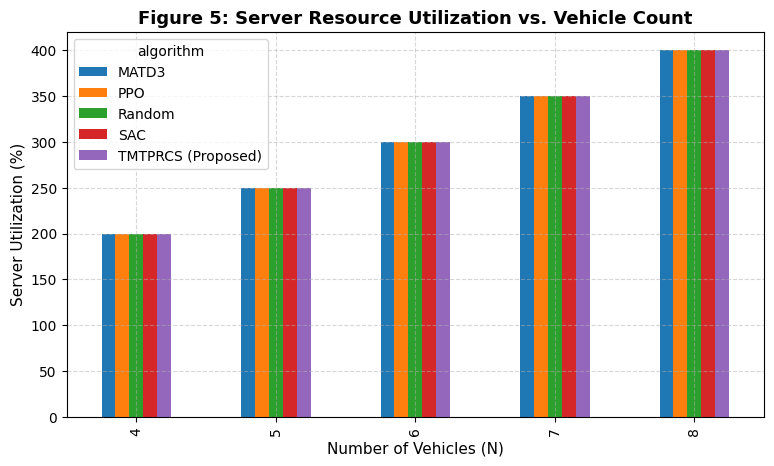

In [17]:
pivot_util = sweep_df.pivot(index='N', columns='algorithm', values='server_utilization_pct')
pivot_util.plot(kind='bar', figsize=(9, 5))
plt.title("Figure 5: Server Resource Utilization vs. Vehicle Count", fontsize=13, fontweight='bold')
plt.xlabel("Number of Vehicles (N)", fontsize=11)
plt.ylabel("Server Utilization (%)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("fig5_resource_utilization.png", dpi=300, bbox_inches='tight')
plt.show()

## 12. Figure 6 – Per-Vehicle Satisfaction Utility

Compares average per-vehicle utility across different vehicle counts. Exports fig6_per_vehicle_utility.png.

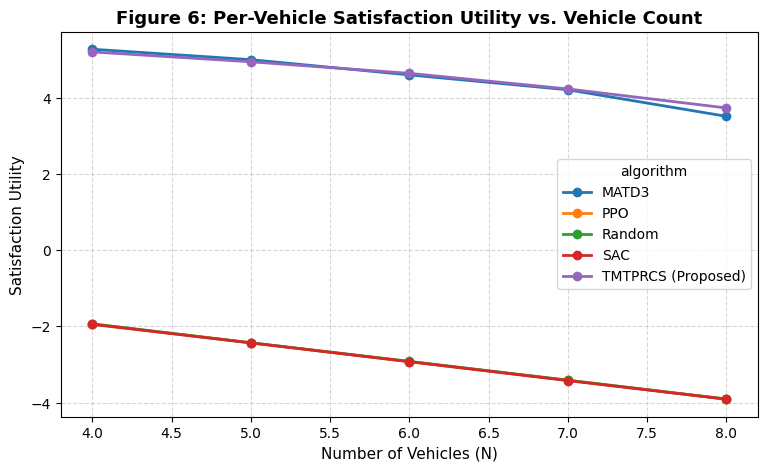

In [18]:
pivot_util_val = sweep_df.pivot(index='N', columns='algorithm', values='per_vehicle_utility_mean')
pivot_util_val.plot(marker='o', linewidth=2, figsize=(9, 5))
plt.title("Figure 6: Per-Vehicle Satisfaction Utility vs. Vehicle Count", fontsize=13, fontweight='bold')
plt.xlabel("Number of Vehicles (N)", fontsize=11)
plt.ylabel("Satisfaction Utility", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("fig6_per_vehicle_utility.png", dpi=300, bbox_inches='tight')
plt.show()

## 13. Figure 7a – Digital Twin Maintenance Delay

Compares digital-twin maintenance delay and displays the 100 ms deadline. Exports fig7a_twin_delay.png.

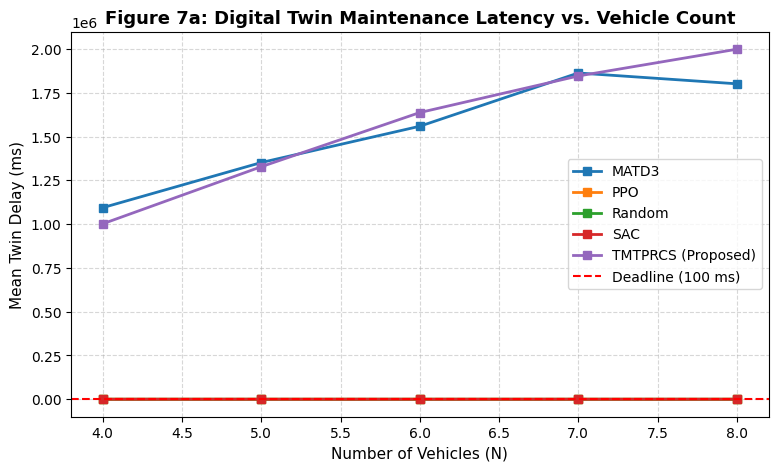

In [19]:
pivot_dt = sweep_df.pivot(index='N', columns='algorithm', values='dt_delay_mean_ms')
pivot_dt.plot(marker='s', linewidth=2, figsize=(9, 5))
plt.axhline(y=100, color='r', linestyle='--', label='Deadline (100 ms)')
plt.title("Figure 7a: Digital Twin Maintenance Latency vs. Vehicle Count", fontsize=13, fontweight='bold')
plt.xlabel("Number of Vehicles (N)", fontsize=11)
plt.ylabel("Mean Twin Delay (ms)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.savefig("fig7a_twin_delay.png", dpi=300, bbox_inches='tight')
plt.show()

## 14. Figure 7b – Task Processing Delay

Compares task-processing delay and displays the 500 ms deadline. Exports fig7b_task_delay.png.

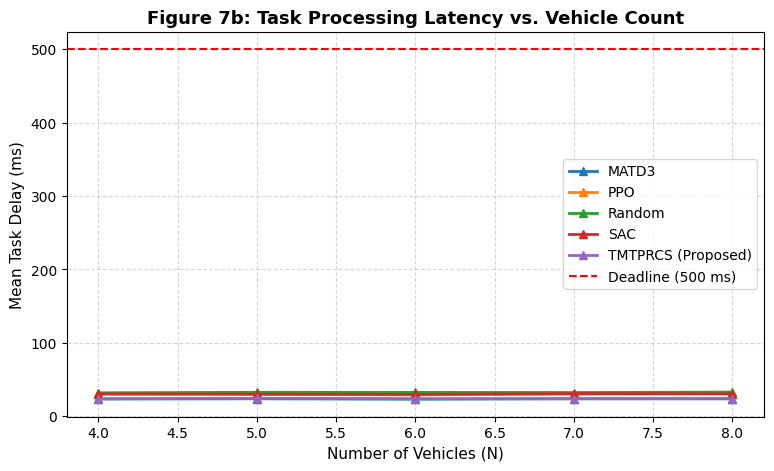

In [20]:
pivot_tk = sweep_df.pivot(index='N', columns='algorithm', values='task_delay_mean_ms')
pivot_tk.plot(marker='^', linewidth=2, figsize=(9, 5))
plt.axhline(y=500, color='r', linestyle='--', label='Deadline (500 ms)')
plt.title("Figure 7b: Task Processing Latency vs. Vehicle Count", fontsize=13, fontweight='bold')
plt.xlabel("Number of Vehicles (N)", fontsize=11)
plt.ylabel("Mean Task Delay (ms)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.savefig("fig7b_task_delay.png", dpi=300, bbox_inches='tight')
plt.show()

## 15. Experiment 2 – Figure Export Confirmation

Confirms that all four vehicle-density comparison figures have been exported.

In [21]:
print("[SAVED] Figures 5, 6, 7a, and 7b exported successfully.")

## 16. Experiment 3 – Multi-Seed Stability Setup

Initializes five random seeds (42–46) and creates lists for storing reward and deadline-satisfaction results.

**Purpose:** Multiple seeds help evaluate the consistency of the proposed algorithm.

In [22]:
# Cell 10: Multi-Seed Variance & Stability Analysis for TMTPRCS (N = 7)
print("="*70)
print("EXPERIMENT 3: MULTI-SEED VARIANCE EVALUATION FOR TMTPRCS (N = 7)")
print("="*70)

seeds = [42, 43, 44, 45, 46]
seed_rewards = []
seed_dt_sats = []
seed_tk_sats = []

## 17. Experiment 3 – Training and Evaluation Across Seeds

Trains a fresh TMTPRCS agent for 300 episodes for each seed. Evaluates the trained agent and records the results.

In [23]:
for s in seeds:
    seed_env = VECEnvironment(num_vehicles=7, seed=s)
    tmtprcs_seed = TMTPRCS(num_agents=7)
    for ep in range(300):
        obs = seed_env.reset()
        for t in range(10):
            actions = tmtprcs_seed.act(obs, explore=True)
            next_obs, rewards, info = seed_env.step(actions)
            tmtprcs_seed.buffer.push(obs, actions, rewards, next_obs)
            tmtprcs_seed.train_step(batch_size=64)
            obs = next_obs
        tmtprcs_seed.decay_epsilon()

    eval_m = evaluate_agent(tmtprcs_seed, seed_env, episodes=20)
    seed_rewards.append(eval_m['avg_reward'])
    seed_dt_sats.append(eval_m['dt_deadline_sat_ratio'])
    seed_tk_sats.append(eval_m['task_deadline_sat_ratio'])
    print(f"Seed {s} -> Reward: {eval_m['avg_reward']:.4f}, Twin Sat Ratio: {eval_m['dt_deadline_sat_ratio']*100:.1f}%, Task Sat Ratio: {eval_m['task_deadline_sat_ratio']*100:.1f}%")

## 18. Experiment 3 – Multi-Seed Stability Summary

Calculates the mean and standard deviation of satisfaction utility and deadline satisfaction across the five independent runs.

In [24]:
print("\nTMTPRCS Multi-Seed Stability Summary (5 Seeds):")
print(f"Average Satisfaction Utility: {np.mean(seed_rewards):.4f} +/- {np.std(seed_rewards):.4f}")
print(f"Twin Deadline Satisfaction:  {np.mean(seed_dt_sats)*100:.2f}% +/- {np.std(seed_dt_sats)*100:.2f}%")
print(f"Task Deadline Satisfaction:  {np.mean(seed_tk_sats)*100:.2f}% +/- {np.std(seed_tk_sats)*100:.2f}%")

## 19. Package and Download Experiment Results

Collects the log file, generated figures and CSV summaries into simulation_results_v6.zip.

**Purpose:** Run this cell after all experiments finish. In Google Colab, the ZIP file is downloaded automatically.

In [25]:
# Cell 11: Packaging Experiment Artifacts & Triggering Direct Colab Download
print("="*70)
print("PACKAGING EXPERIMENT RESULTS AND TRIGGERING AUTOMATIC DOWNLOAD")
print("="*70)

zip_filename = "simulation_results_v6.zip"
files_to_zip = [
    "console_output_v6.log",
    "fig4_convergence_N7.png",
    "fig5_resource_utilization.png",
    "fig6_per_vehicle_utility.png",
    "fig7a_twin_delay.png",
    "fig7b_task_delay.png",
    "comparison_summary_N7.csv",
    "vehicle_sweep_summary.csv"
]

with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for f in files_to_zip:
        if os.path.exists(f):
            zipf.write(f)
            print(f"Added to zip: {f}")

print(f"\n[SUCCESS] All output files packaged into '{zip_filename}'.")

if COLAB_ENV:
    print(f"[DOWNLOAD TRIGGERED] '{zip_filename}' download initiated in your browser!")
    files.download(zip_filename)
else:
    print(f"[LOCAL RUN] Results file ready at '{zip_filename}'.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>